In [84]:
import pandas as pd
import numpy as np      
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')   
import sklearn as sk 

from sklearn.model_selection import train_test_split 
from sklearn.metrics import mutual_info_score 
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

In [54]:
import os 
os.getcwd()

df = pd.read_csv('../data/course_lead_scoring_2026.csv') 
print(df.head())

      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  


In [55]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [56]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [22]:
df.shape

(5000, 9)

In [23]:
display(df.describe())

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [24]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB
None


In [25]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [26]:
display(df.describe())

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [67]:
cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
df[cat_cols] = df[cat_cols].fillna('N/A')

num_cols = ['annual_income', 'lead_score']
df[num_cols] = df[num_cols].fillna(0)

In [68]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [69]:
display(df.head())

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,N/A,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [70]:
df['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
N/A               240
Name: count, dtype: int64

In [71]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '') 
categorical_columns = df.select_dtypes(include=['object']).columns 

In [72]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [73]:
df['converted'].value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

In [74]:
df['converted'].mean()

np.float64(0.5766)

In [62]:
display(df.columns)

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

Correlation Matrix of Numerical Features:


,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.137542,0.106375,0.231396,0.181752
number_of_courses_viewed,0.137542,1.000000,0.721609,0.769352,0.395038
interaction_count,0.106375,0.721609,1.000000,0.928712,0.448624
lead_score,0.231396,0.769352,0.928712,1.000000,0.490206
converted,0.181752,0.395038,0.448624,0.490206,1.000000


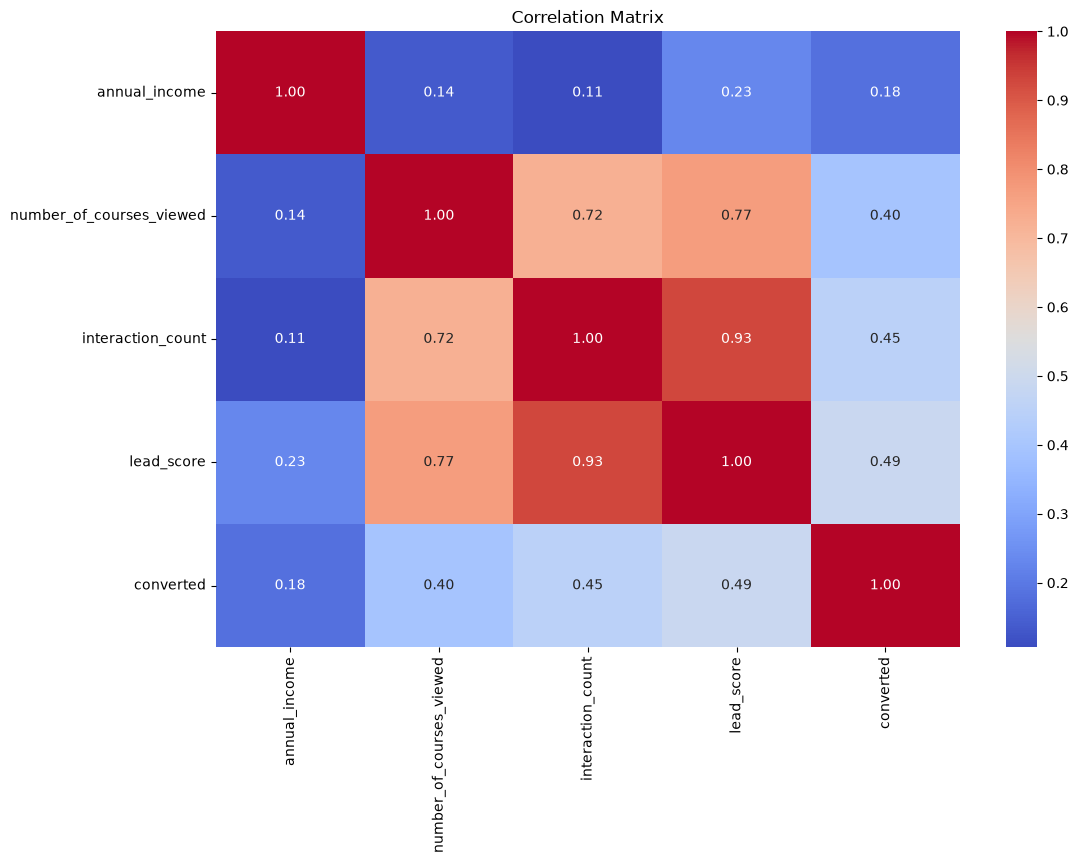

In [63]:
# Select only numerical features
numeric_df = df.select_dtypes(include=[np.number])

# Compute correlation coefficient for every pair of numerical features
corr_matrix = numeric_df.corr()

# Display the matrix
print('Correlation Matrix of Numerical Features:')
display(corr_matrix)

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()


In [85]:
X = df.drop(columns=['converted'])
y = df['converted']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Keep a validation split for later model tuning
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

# One-hot encode categorical columns using the training split only
cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
encoded_train = pd.get_dummies(X_train[cat_cols], columns=cat_cols)

# Mutual information for each one-hot encoded feature against the target
mi_scores = {col: mutual_info_score(y_train, encoded_train[col]) for col in encoded_train.columns}
mi_df = pd.DataFrame(
    {
        'feature': list(mi_scores.keys()),
        'mutual_information': list(mi_scores.values())
    }
).sort_values('mutual_information', ascending=False)

display(mi_df)

,feature,mutual_information
14,employment_status_employed,1.976608e-02
3,lead_source_paid_ads,1.326788e-02
4,lead_source_referral,1.322218e-02
17,employment_status_unemployed,1.045934e-02
1,lead_source_events,6.434106e-03
2,lead_source_organic_search,6.429931e-03
16,employment_status_student,6.222154e-03
12,industry_technology,1.625958e-03
7,industry_education,1.037004e-03
23,location_south_america,4.444566e-04


In [86]:
# One-hot encoded categorical features with target only from the training split
encoded_train = pd.get_dummies(X_train[cat_cols], columns=cat_cols)
mi_values = {col: mutual_info_score(y_train, encoded_train[col]) for col in encoded_train.columns}

mi_df_encoded = pd.DataFrame(
    {
        'feature': list(mi_values.keys()),
        'mutual_information': list(mi_values.values())
    }
).sort_values('mutual_information', ascending=False)

display(mi_df_encoded)

,feature,mutual_information
14,employment_status_employed,1.976608e-02
3,lead_source_paid_ads,1.326788e-02
4,lead_source_referral,1.322218e-02
17,employment_status_unemployed,1.045934e-02
1,lead_source_events,6.434106e-03
2,lead_source_organic_search,6.429931e-03
16,employment_status_student,6.222154e-03
12,industry_technology,1.625958e-03
7,industry_education,1.037004e-03
23,location_south_america,4.444566e-04


In [90]:
# Prepare data for modeling
for col in cat_cols:
    X_train[col] = X_train[col].fillna('N/A')
    X_val[col] = X_val[col].fillna('N/A')

for col in ['annual_income', 'lead_score']:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_val[col] = X_val[col].fillna(median_value)

X_train_model = pd.get_dummies(X_train, columns=cat_cols)
X_val_model = pd.get_dummies(X_val, columns=cat_cols)
X_val_model = X_val_model.reindex(columns=X_train_model.columns, fill_value=0)

# Reproducible logistic regression model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train_model, y_train)

# Validation accuracy rounded to 2 decimal digits
val_accuracy = model.score(X_val_model, y_val)
print(round(val_accuracy, 2))

0.66
